In [0]:
import pyspark.sql.functions as F

df_netflix = spark.read.csv("/Volumes/workspace/default/datos_netflix/netflix_clean.csv", header=True, inferSchema=True, quote='"', escape='"')
df_netflix.createOrReplaceTempView("netflix_clean")

df_mapreduce = spark.read.csv("/Volumes/workspace/default/datos_netflix/mapreduce_actores.csv", header=True, inferSchema=True)
df_mapreduce.createOrReplaceTempView("mapreduce_actores")

print("=== COMPROBACIÓN DE TABLAS ===")
print(f"Registros en netflix_clean: {df_netflix.count()}")
print(f"Actores en mapreduce_actores: {df_mapreduce.count()}")
display(df_netflix.limit(5))
display(df_mapreduce.limit(5))

=== COMPROBACIÓN DE TABLAS ===
Registros en netflix_clean: 8807
Actores en mapreduce_actores: 36439


show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_min
s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,null,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable.",90
s2,TV Show,Blood & Water,null,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Natasha Thahane, Arno Greeff, Xolile Tshabalala, Getmore Sithole, Cindy Mahlangu, Ryle De Morny, Greteli Fincham, Sello Maake Ka-Ncube, Odwa Gwanya, Mekaila Mathys, Sandi Schultz, Duane Williams, Shamilla Miller, Patrick Mofokeng",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth.",null
s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noureddine Farihi, Geert Van Rampelberg, Bakary Diombera",null,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure","To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robbers are pulled into a violent and deadly turf war.",null
s4,TV Show,Jailbirds New Orleans,null,null,null,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice Center in New Orleans on this gritty reality series.",null
s5,TV Show,Kota Factory,null,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, Ahsaas Channa, Revathi Pillai, Urvi Singh, Arun Kumar",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV Comedies","In a city of coaching centers known to train India’s finest collegiate minds, an earnest but unexceptional student and his friends navigate campus life.",null


actor,cantidad_titulos
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Naseeruddin Shah,32
Takahiro Sakurai,32


In [0]:
df_a_pyspark = df_netflix.fillna({'type': 'Sin clasificación'}) \
    .groupBy("type") \
    .agg(F.countDistinct("show_id").alias("cantidad_titulos")) \
    .withColumnRenamed("type", "tipo") \
    .orderBy(F.col("cantidad_titulos").desc())
    
df_a_pyspark.createOrReplaceTempView("analisis_a_pyspark")
display(df_a_pyspark)

tipo,cantidad_titulos
Movie,6131
TV Show,2676


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW analisis_a_sql AS
SELECT
    COALESCE(type, 'Sin clasificación') AS tipo,
    COUNT(DISTINCT show_id) AS cantidad_titulos
FROM netflix_clean
GROUP BY type
ORDER BY cantidad_titulos DESC;

SELECT * FROM analisis_a_sql;

tipo,cantidad_titulos
Movie,6131
TV Show,2676


In [0]:
df_b_pyspark = df_netflix.filter(F.col("cast").isNotNull()) \
    .withColumn("actor_array", F.split(F.col("cast"), ",")) \
    .withColumn("actor_raw", F.explode(F.col("actor_array"))) \
    .withColumn("actor", F.trim(F.col("actor_raw"))) \
    .filter(F.col("actor") != "") \
    .groupBy("actor") \
    .agg(F.countDistinct("show_id").alias("cantidad_titulos")) \
    .orderBy(F.col("cantidad_titulos").desc(), F.col("actor").asc())
    
df_b_pyspark.createOrReplaceTempView("analisis_b_pyspark")
display(df_b_pyspark)

actor,cantidad_titulos
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Naseeruddin Shah,32
Takahiro Sakurai,32
Rupa Bhimani,31
Akshay Kumar,30
Om Puri,30
Yuki Kaji,29
Amitabh Bachchan,28


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW analisis_b_sql AS
SELECT 
    TRIM(actor_raw) AS actor,
    COUNT(DISTINCT show_id) AS cantidad_titulos
FROM (
    SELECT show_id, EXPLODE(SPLIT(cast, ',')) AS actor_raw
    FROM netflix_clean
    WHERE cast IS NOT NULL
)
WHERE TRIM(actor_raw) != ''
GROUP BY TRIM(actor_raw)
ORDER BY cantidad_titulos DESC, actor ASC;

SELECT * FROM analisis_b_sql;

actor,cantidad_titulos
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Naseeruddin Shah,32
Takahiro Sakurai,32
Rupa Bhimani,31
Akshay Kumar,30
Om Puri,30
Yuki Kaji,29
Amitabh Bachchan,28


In [0]:
df_c_pyspark = df_netflix.filter((F.col("type") == "Movie") & (F.col("duration_min") > 0) & F.col("country").isNotNull()) \
    .withColumn("country_array", F.split(F.col("country"), ",")) \
    .withColumn("country_raw", F.explode(F.col("country_array"))) \
    .withColumn("pais", F.trim(F.col("country_raw"))) \
    .filter(F.col("pais") != "") \
    .groupBy("pais") \
    .agg(
        F.countDistinct("show_id").alias("cantidad_peliculas"),
        F.round(F.avg("duration_min"), 2).alias("duracion_promedio_min")
    ) \
    .orderBy(F.col("cantidad_peliculas").desc(), F.col("pais").asc())
    
df_c_pyspark.createOrReplaceTempView("analisis_c_pyspark")
display(df_c_pyspark)

pais,cantidad_peliculas,duracion_promedio_min
United States,2749,93.75
India,962,125.91
United Kingdom,534,98.76
Canada,319,91.15
France,303,100.97
Germany,182,103.01
Spain,171,101.1
Japan,119,98.85
China,114,104.46
Mexico,111,90.6


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW analisis_c_sql AS
SELECT 
    TRIM(country_raw) AS pais,
    COUNT(DISTINCT show_id) AS cantidad_peliculas,
    ROUND(AVG(duration_min), 2) AS duracion_promedio_min
FROM (
    SELECT show_id, duration_min, EXPLODE(SPLIT(country, ',')) AS country_raw
    FROM netflix_clean
    WHERE type = 'Movie' AND duration_min > 0 AND country IS NOT NULL
)
WHERE TRIM(country_raw) != ''
GROUP BY TRIM(country_raw)
ORDER BY cantidad_peliculas DESC, pais ASC;

SELECT * FROM analisis_c_sql;


pais,cantidad_peliculas,duracion_promedio_min
United States,2749,93.75
India,962,125.91
United Kingdom,534,98.76
Canada,319,91.15
France,303,100.97
Germany,182,103.01
Spain,171,101.1
Japan,119,98.85
China,114,104.46
Mexico,111,90.6


In [0]:
df_a_sql = spark.sql("SELECT * FROM analisis_a_sql")
df_b_sql = spark.sql("SELECT * FROM analisis_b_sql")
df_c_sql = spark.sql("SELECT * FROM analisis_c_sql")

print("=== TABLA 3: VERIFICACIÓN DE SQL Y PYSPARK ===")
def comparar(nombre, df_sql, df_py):
    sql_count = df_sql.count()
    py_count = df_py.count()
    filas_solo_sql = df_sql.subtract(df_py).count()
    filas_solo_py = df_py.subtract(df_sql).count()
    filas_diferentes = filas_solo_sql + filas_solo_py
    una_sola_salida = max(0, abs(sql_count - py_count))
    coinciden = "Sí" if filas_diferentes == 0 else "No"
    
    print(f"Análisis: {nombre}")
    print(f"  Filas SQL: {sql_count}")
    print(f"  Filas PySpark: {py_count}")
    print(f"  Filas con valores diferentes: {filas_diferentes}")
    print(f"  Filas presentes en una sola salida: {una_sola_salida}")
    print(f"  ¿Coinciden completamente?: {coinciden}\n")

comparar("Películas y series", df_a_sql, df_a_pyspark)
comparar("Títulos por actor", df_b_sql, df_b_pyspark)
comparar("Duración por país", df_c_sql, df_c_pyspark)

=== TABLA 3: VERIFICACIÓN DE SQL Y PYSPARK ===
Análisis: Películas y series
  Filas SQL: 2
  Filas PySpark: 2
  Filas con valores diferentes: 0
  Filas presentes en una sola salida: 0
  ¿Coinciden completamente?: Sí

Análisis: Títulos por actor
  Filas SQL: 36439
  Filas PySpark: 36399
  Filas con valores diferentes: 248
  Filas presentes en una sola salida: 40
  ¿Coinciden completamente?: No

Análisis: Duración por país
  Filas SQL: 117
  Filas PySpark: 117
  Filas con valores diferentes: 0
  Filas presentes en una sola salida: 0
  ¿Coinciden completamente?: Sí



In [0]:
df_join = df_mapreduce.alias("mr").join(
    df_b_pyspark.alias("sp"),
    on="actor",
    how="full_outer"
).select(
    F.col("actor"),
    F.col("mr.cantidad_titulos").alias("cant_mr"),
    F.col("sp.cantidad_titulos").alias("cant_sp")
)

actores_mr = df_mapreduce.count()
actores_sp = df_b_pyspark.count()
iguales = df_join.filter(F.col("cant_mr") == F.col("cant_sp")).count()
diferentes = df_join.filter((F.col("cant_mr").isNotNull()) & (F.col("cant_sp").isNotNull()) & (F.col("cant_mr") != F.col("cant_sp"))).count()
solo_mr = df_join.filter(F.col("cant_sp").isNull()).count()
solo_sp = df_join.filter(F.col("cant_mr").isNull()).count()

print("=== TABLA 4: COMPARACIÓN DE LOS DIEZ PRIMEROS ACTORES ===")
df_top10 = df_join.orderBy(F.desc_nulls_last("cant_sp"), F.col("actor").asc()).limit(10)
df_top10_diff = df_top10.withColumn("Diferencia MapReduce menos Spark", F.col("cant_mr") - F.col("cant_sp"))
df_top10_diff.show(truncate=False)

print("=== TABLA 5: VERIFICACIÓN COMPLETA DE MAPREDUCE Y SPARK ===")
print(f"Actores en MapReduce: {actores_mr}")
print(f"Actores en Spark: {actores_sp}")
print(f"Actores presentes en ambas salidas con cantidades iguales: {iguales}")
print(f"Actores presentes en ambas salidas con cantidades diferentes: {diferentes}")
print(f"Actores presentes únicamente en MapReduce: {solo_mr}")
print(f"Actores presentes únicamente en Spark: {solo_sp}")

=== TABLA 4: COMPARACIÓN DE LOS DIEZ PRIMEROS ACTORES ===
+----------------+-------+-------+--------------------------------+
|actor           |cant_mr|cant_sp|Diferencia MapReduce menos Spark|
+----------------+-------+-------+--------------------------------+
|Anupam Kher     |43     |43     |0                               |
|Shah Rukh Khan  |35     |35     |0                               |
|Julie Tejwani   |33     |33     |0                               |
|Naseeruddin Shah|32     |32     |0                               |
|Takahiro Sakurai|32     |32     |0                               |
|Rupa Bhimani    |31     |31     |0                               |
|Akshay Kumar    |30     |30     |0                               |
|Om Puri         |30     |30     |0                               |
|Yuki Kaji       |29     |29     |0                               |
|Amitabh Bachchan|28     |28     |0                               |
+----------------+-------+-------+------------------------

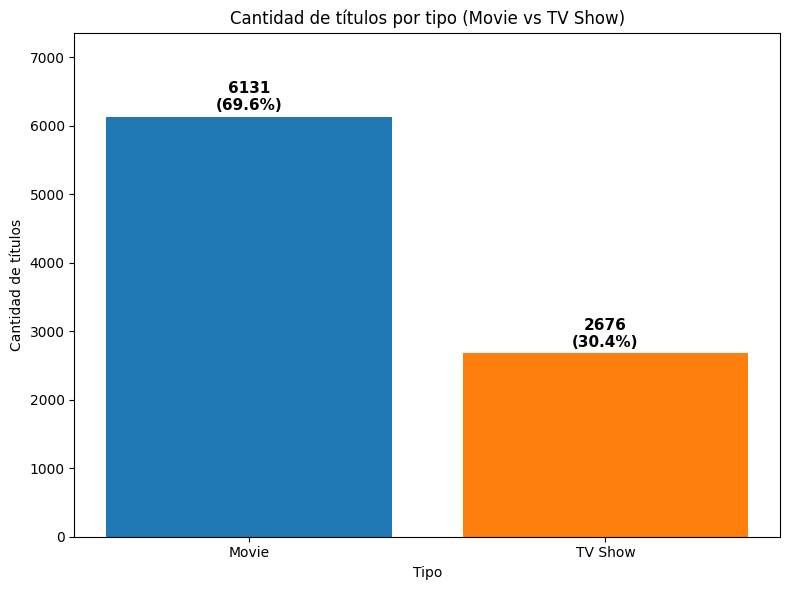

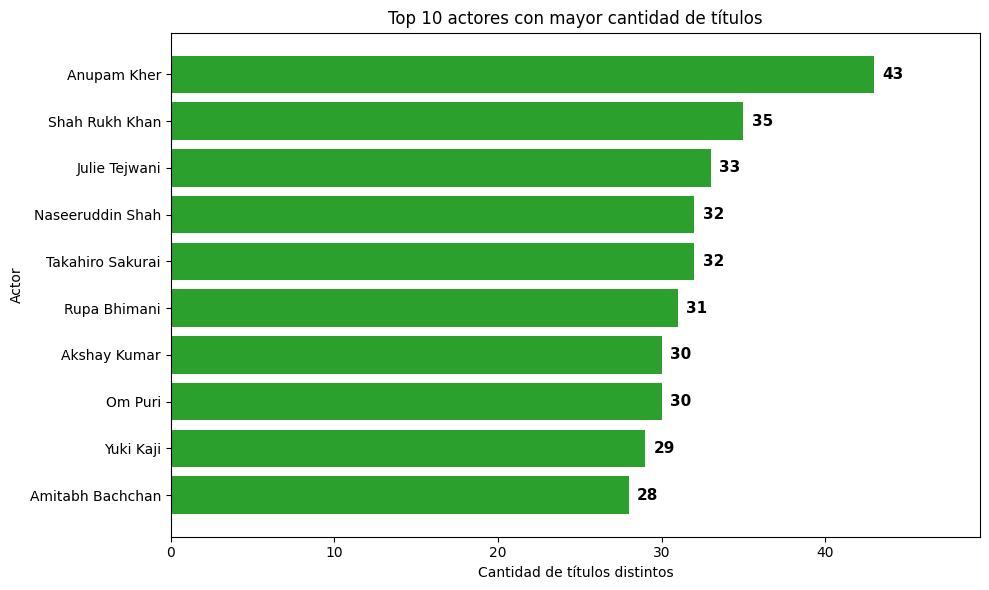

=== TABLA 6: DURACIÓN DE PELÍCULAS POR PAÍS (Top 10) ===
+--------------+------------------+---------------------+
|pais          |cantidad_peliculas|duracion_promedio_min|
+--------------+------------------+---------------------+
|United States |2749              |93.75                |
|India         |962               |125.91               |
|United Kingdom|534               |98.76                |
|Canada        |319               |91.15                |
|France        |303               |100.97               |
|Germany       |182               |103.01               |
|Spain         |171               |101.1                |
|Japan         |119               |98.85                |
|China         |114               |104.46               |
|Mexico        |111               |90.6                 |
+--------------+------------------+---------------------+



In [0]:
import matplotlib.pyplot as plt
import pandas as pd

# --- 1. GRÁFICO DE PELÍCULAS Y SERIES ---
# Traer datos a Pandas y filtrar solo Movie y TV Show
pdf_a = df_a_pyspark.toPandas()
pdf_a_filtered = pdf_a[pdf_a['tipo'].isin(['Movie', 'TV Show'])].copy()
total_clasificados = pdf_a_filtered['cantidad_titulos'].sum()

# Dibujar barras
fig1, ax1 = plt.subplots(figsize=(8, 6))
barras = ax1.bar(pdf_a_filtered['tipo'], pdf_a_filtered['cantidad_titulos'], color=['#1f77b4', '#ff7f0e'])

ax1.set_title("Cantidad de títulos por tipo (Movie vs TV Show)")
ax1.set_xlabel("Tipo")
ax1.set_ylabel("Cantidad de títulos")
ax1.set_ylim(0, pdf_a_filtered['cantidad_titulos'].max() * 1.2) # Espacio para el texto

# Porcentaje y cantidad sobre cada barra
for barra in barras:
    altura = barra.get_height()
    porcentaje = (altura / total_clasificados) * 100
    texto = f"{altura}\n({porcentaje:.1f}%)"
    ax1.text(barra.get_x() + barra.get_width()/2., altura + 50, texto, ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# --- 2. GRÁFICO DE ACTORES ---
# Tomar top 10 e invertir orden para que el mayor quede arriba en el gráfico horizontal
pdf_b = df_b_pyspark.limit(10).toPandas().iloc[::-1]

fig2, ax2 = plt.subplots(figsize=(10, 6))
barras2 = ax2.barh(pdf_b['actor'], pdf_b['cantidad_titulos'], color='#2ca02c')

ax2.set_title("Top 10 actores con mayor cantidad de títulos")
ax2.set_xlabel("Cantidad de títulos distintos")
ax2.set_ylabel("Actor")
ax2.set_xlim(0, pdf_b['cantidad_titulos'].max() * 1.15)

# Etiqueta numérica al lado de la barra
for barra in barras2:
    ancho = barra.get_width()
    ax2.text(ancho + 0.5, barra.get_y() + barra.get_height()/2., f"{int(ancho)}", ha='left', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# --- 3. TABLA 6: DURACIÓN DE PELÍCULAS POR PAÍS ---
print("=== TABLA 6: DURACIÓN DE PELÍCULAS POR PAÍS (Top 10) ===")
df_c_top10 = df_c_pyspark.limit(10)
df_c_top10.show(truncate=False)